# Toy Example using CSET

`Pyxu` is a very new library constantly under update. This notebook helps fixing the CSET code when the reconstruction do not work after a new update. It is also here to explore the different tricks of the trades in the CSET methodology. For example, test CSET without normalizing the data. Given realistic scales, the method won't work. 

## 📦 Imports

In [1]:
import numpy as np 
import pyvista as pv
import scipy as sp
import pygsp
import mindmap as mm

import pyxu.abc as pxa
import pyxu.operator as pxo 
import pyxu.opt.stop as pxst
from pyxu.opt.solver import PGD

## 🧠 Data

In [2]:
def generate_points_on_sphere(n_points):
    # Randomly generate points uniformly on the surface of a sphere
    phi = np.arccos(2 * np.random.rand(n_points) - 1)  # Polar angle, uniformly distributed
    theta = 2 * np.pi * np.random.rand(n_points)  # Azimuthal angle, uniformly distributed

    # Convert spherical coordinates to Cartesian coordinates
    x = np.sin(phi) * np.cos(theta)
    y = np.sin(phi) * np.sin(theta)
    z = np.cos(phi)

    return np.array([x, y, z]).T

# generate positions
sources = generate_points_on_sphere(1000)
sensors = generate_points_on_sphere(100)*2

# generate forward solution
forward = 1/np.linalg.norm(np.tile(sensors[:,:,None], (1,1,len(sources))) - sources.T[None,:,:], axis=1)*1e3

# generate source connections
tree = sp.spatial.KDTree(sources)
dd, ii = tree.query(sources, k=5)

conn = np.zeros((len(sources), len(sources)))
for i in range(len(sources)):
    conn[i, ii[i]] = 1
conn = conn - np.eye(len(sources))
conn = conn + conn.T

# generate source signal
G = pygsp.graphs.Graph(conn, lap_type="normalized", coords=sources)
G.compute_fourier_basis()
cst = G.U.T

alpha = np.zeros(len(sources))
alpha[[1,3,5,10]] = 1

src_signal = (cst.T @ alpha)*1e-9

# generate sensor signal
sen_signal = forward @ src_signal

#### 🌟 Visualize ground truth

In [3]:
src = pv.PolyData(sources)
sen = pv.PolyData(sensors)

src["ground truth"] = src_signal 
sen["sensors"]      = sen_signal

p = pv.Plotter()
p.add_mesh(src, scalars="ground truth", render_points_as_spheres=True, point_size=10, cmap="RdBu")
p.add_mesh(sen, point_size=8, cmap="RdBu")
p.show()

Widget(value='<iframe src="http://localhost:39913/index.html?ui=P_0x743326deeae0_0&reconnect=auto" class="pyvi…

#### 🌟 Visualize connections

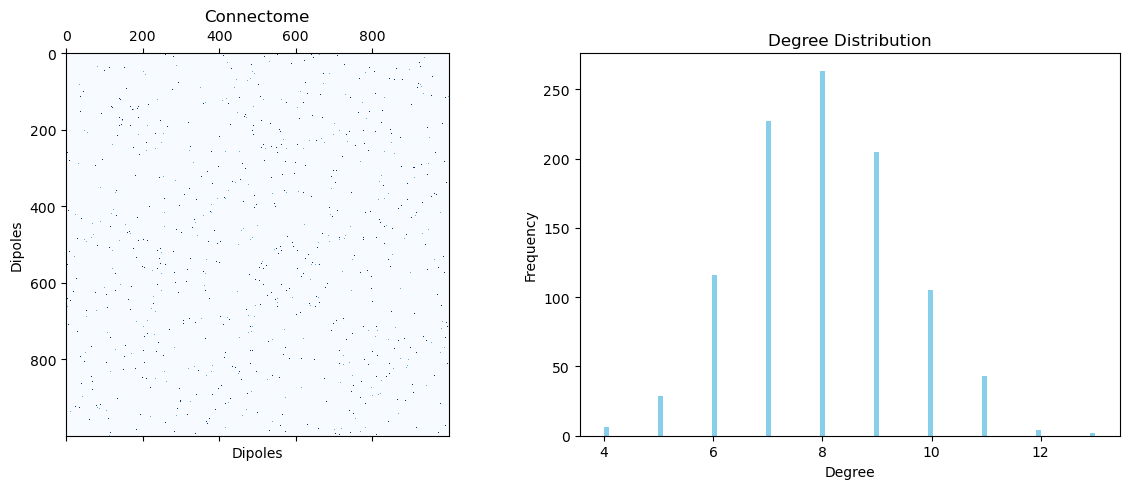

In [4]:
mm.viz.plot_connectome(conn)

⚙️ <font color=green>**Solve inverse problem with CSET**</font>: PGD version

In [41]:
# regularizer parameter
lam1 = 0.1
lam2 = 0.5

# forward * connectome spectrum
A = forward @ cst.T
A = pxa.LinOp.from_array(A)

# L1 norm
l1_norm = lam1*pxo.L1Norm(dim_shape=A.dim_shape)

# L2 norm 
l2_norm = lam2*pxo.SquaredL2Norm(dim_shape=A.dim_shape)

# initial guess
alpha0 = np.zeros(A.dim_shape)

# stopping criterion (number of iteration only)
sc = pxst.MaxIter(1000)

b = sen_signal
b = b/np.linalg.norm(b)

l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-b)*A + l2_norm
l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

#f = l22_loss + l2_norm 
#f.diff_lipschitz = l22_loss.diff_lipschitz + l2_norm.diff_lipschitz 

solver = PGD(f=l22_loss, g=l1_norm)
alpha
solver.fit(x0=alpha0, stop_crit=sc)

recon_alpha = solver.solution().squeeze()
recon = cst.T @ recon_alpha * np.linalg.norm(b)

INFO -- [2024-12-05 13:38:57.504541] Iteration 0
	iteration: 0
	N_iter: 1
INFO -- [2024-12-05 13:38:57.505860] Iteration 1
	iteration: 1
	N_iter: 2
INFO -- [2024-12-05 13:38:57.506668] Iteration 2
	iteration: 2
	N_iter: 3
INFO -- [2024-12-05 13:38:57.507525] Iteration 3
	iteration: 3
	N_iter: 4
INFO -- [2024-12-05 13:38:57.510826] Iteration 4
	iteration: 4
	N_iter: 5
INFO -- [2024-12-05 13:38:57.511559] Iteration 5
	iteration: 5
	N_iter: 6
INFO -- [2024-12-05 13:38:57.512111] Iteration 6
	iteration: 6
	N_iter: 7
INFO -- [2024-12-05 13:38:57.512838] Iteration 7
	iteration: 7
	N_iter: 8
INFO -- [2024-12-05 13:38:57.513355] Iteration 8
	iteration: 8
	N_iter: 9
INFO -- [2024-12-05 13:38:57.513877] Iteration 9
	iteration: 9
	N_iter: 10
INFO -- [2024-12-05 13:38:57.515906] Iteration 10
	iteration: 10
	N_iter: 11
INFO -- [2024-12-05 13:38:57.521299] Iteration 11
	iteration: 11
	N_iter: 12
INFO -- [2024-12-05 13:38:57.523258] Iteration 12
	iteration: 12
	N_iter: 13
INFO -- [2024-12-05 13:38:57

#### 🌟 Visualize reconstruction

In [40]:
src2 = pv.PolyData(sources-[3,-3,0])
src2["recon"] = recon

p2 = pv.Plotter()
p2.add_mesh(src, scalars="ground truth", render_points_as_spheres=True, point_size=10, cmap="RdBu")
p2.add_mesh(src2, scalars="recon", render_points_as_spheres=True, point_size=10, cmap="RdBu")
p2.show()

Widget(value='<iframe src="http://localhost:39913/index.html?ui=P_0x743304521460_12&reconnect=auto" class="pyv…

⚙️ <font color=green>**Solve inverse problem with CSET**</font>: Loris Verhoeven version

In [23]:
from pyxu.opt.solver import LorisVerhoeven

# regularizer parameter
lam = 0.1

# forward
A = forward
A = pxa.LinOp.from_array(A)

# connectome spectrum transform
K = cst
K = pxa.LinOp.from_array(K)

# L1 norm
l1_norm = lam*pxo.L1Norm(dim_shape=A.dim_shape)

# initial guess
recon0 = np.zeros(A.dim_shape)

# stopping criterion (number of iteration only)
sc = pxst.MaxIter(10000)

b = sen_signal
b = b/np.linalg.norm(b)

l22_loss = pxo.SquaredL2Norm(dim_shape=A.codim_shape).argshift(-b)*A
l22_loss.diff_lipschitz = l22_loss.estimate_diff_lipschitz()

solver = LorisVerhoeven(f=l22_loss, h=l1_norm)

solver.fit(x0=recon0, stop_crit=sc)

recon = solver.solution().squeeze() * np.linalg.norm(b)

INFO -- [2024-12-05 10:40:44.408099] Iteration 0
	iteration: 0
	N_iter: 1
INFO -- [2024-12-05 10:40:44.408810] Iteration 1
	iteration: 1
	N_iter: 2
INFO -- [2024-12-05 10:40:44.409393] Iteration 2
	iteration: 2
	N_iter: 3
INFO -- [2024-12-05 10:40:44.409906] Iteration 3
	iteration: 3
	N_iter: 4
INFO -- [2024-12-05 10:40:44.410618] Iteration 4
	iteration: 4
	N_iter: 5
INFO -- [2024-12-05 10:40:44.411028] Iteration 5
	iteration: 5
	N_iter: 6
INFO -- [2024-12-05 10:40:44.411468] Iteration 6
	iteration: 6
	N_iter: 7
INFO -- [2024-12-05 10:40:44.412146] Iteration 7
	iteration: 7
	N_iter: 8
INFO -- [2024-12-05 10:40:44.412557] Iteration 8
	iteration: 8
	N_iter: 9
INFO -- [2024-12-05 10:40:44.413446] Iteration 9
	iteration: 9
	N_iter: 10
INFO -- [2024-12-05 10:40:44.415156] Iteration 10
	iteration: 10
	N_iter: 11
INFO -- [2024-12-05 10:40:44.415637] Iteration 11
	iteration: 11
	N_iter: 12
INFO -- [2024-12-05 10:40:44.416164] Iteration 12
	iteration: 12
	N_iter: 13
INFO -- [2024-12-05 10:40:44

In [24]:
src2 = pv.PolyData(sources-[3,-3,0])
src2["recon"] = recon

p2 = pv.Plotter()
p2.add_mesh(src, scalars="ground truth", render_points_as_spheres=True, point_size=10, cmap="RdBu")
p2.add_mesh(src2, scalars="recon", render_points_as_spheres=True, point_size=10, cmap="RdBu")
p2.show()

Widget(value='<iframe src="http://localhost:39913/index.html?ui=P_0x743328082cf0_10&reconnect=auto" class="pyv…